## Summary Plots and Tables

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scienceplots
import os

from kernelprob.configs.config import *
from kernelprob.utils.datasets import dataset_sizes

plt.style.use('science')

# Load in files into a giant dictionary
# filename format: dataset_estimator_weighting
dataset_names = DATASETS['small_n'] + DATASETS['big_n']


all_weights = [
    'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_16_16',
    'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'beta_shapley_1_16',
    'weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9',
    'beta_shapley_1_1', 
    'banzhaf', # Important to include this last
    'shapley' # Important to include this last
]

weight_lookup = {
    'beta_shapley_1_1' : 'B(1,1)',
    'beta_shapley_2_2' : 'B(2,2)',
    'beta_shapley_4_4' : 'B(4,4)',
    'beta_shapley_8_8' : 'B(8,8)',
    'beta_shapley_16_16' : 'B(16,16)',
    'beta_shapley_1_2' : 'B(1,2)',
    'beta_shapley_1_4' : 'B(1,4)',
    'beta_shapley_1_8' : 'B(1,8)',
    'beta_shapley_1_16' : 'B(1,16)',
    'weighted_banzhaf_0.5' : 'WB(0.5)',
    'weighted_banzhaf_0.6' : 'WB(0.6)',
    'weighted_banzhaf_0.7' : 'WB(0.7)',
    'weighted_banzhaf_0.8' : 'WB(0.8)',
    'weighted_banzhaf_0.9' : 'WB(0.9)',
    'banzhaf' : 'Banzhaf',
    'shapley' : 'Shapley',
}

weightings = {
    'Symmetric Beta' :
        ['beta_shapley_1_1', 'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_16_16'],
    'Asymmetric Beta' : 
        ['beta_shapley_1_1', 'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'beta_shapley_1_16'],
    'Weighted Banzhaf' : 
        ['weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9']
}

def extract_helper(filename, valid_names):
    filename = filename.replace('.csv', '').replace('OFA_S', 'OFAS').replace('GELS_S', 'GELS').split('_', 2)
    if 'OFAS' in filename[0]:
        filename[0] = filename[0].replace('OFAS', 'OFA_S')
    for name in valid_names:
        if name in filename:
            return name
    raise ValueError(f'Could not find any of {valid_names} in filename {filename}')

def load_filtered_error(filter, extra_variable = None, suppress_warnings = True):
    results = {}
    filenames = os.listdir('output')
    for filename in filenames:
        if filename == '.DS_Store' or 'fit_' in filename or 'case_study_' in filename: continue
        # The challenge is that there are extra underscores in the filename that we need to account for
        try:
            dataset = extract_helper(filename, dataset_names)
            estimator = extract_helper(filename, ESTIMATOR_FACTORY.keys())
            weighting = extract_helper(filename, all_weights)
        except ValueError as e:
            if not suppress_warnings:
                print(f'Warning: {e}')
            continue

        # Load in the file
        with open(f'output/{filename}', 'r') as f:
            # Each line is a dictionary, we want to e
            for line in f:
                if 'inf' in line or 'nan' in line: continue
                line = eval(line)
                # Check if the line is valid
                if 'sample_size' in filter:
                    if line['sample_size'] // line['n'] not in filter['sample_size']:
                        continue
                if 'noise' in filter:
                    if line['noise'] not in filter['noise']:
                        continue
                # Add to the results
                if dataset not in results:
                    results[dataset] = {}
                if weighting not in results[dataset]:
                    results[dataset][weighting] = {}
                if estimator not in results[dataset][weighting]:
                    if extra_variable is None:
                        results[dataset][weighting][estimator] = []
                    else:
                        results[dataset][weighting][estimator] = {}
                if extra_variable is None:
                    results[dataset][weighting][estimator].append(line['error'])
                else:
                    if line[extra_variable] not in results[dataset][weighting][estimator]:
                        results[dataset][weighting][estimator][line[extra_variable]] = []  
                    results[dataset][weighting][estimator][line[extra_variable]].append(line['error'])
                    
    return results

def load_fit_error(dataset, ground_truth_class):
    filename = f'output/fit_{dataset}.csv'
    errors = {
        'Linear' : {}, 'RandomForest' : {}, 'XGBoost' : {}
    }
    with open(filename, 'r') as f:
        for line in f:
            dict = eval(line)
            if dict['ground_truth_class'] != ground_truth_class:
                continue
            sm, rm = dict['sample_multiplier'], dict['reg_model_class']
            if sm not in errors[rm]:
                errors[rm][sm] = []
            errors[rm][sm].append(dict['error'])
    return errors

/opt/homebrew/Caskroom/miniconda/base/envs/shapley/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Colors and linestyles for accessible plots
cb_colors = [
    "#D55E00",  # Vermillion
    "#56B4E9",  # Sky Blue
    "#44AA99",  # Teal
    "#AA4499",  # Magenta
    "#009E73",  # Bluish Green
    "#0072B2",  # Blue
    "#E69F00",  # Orange
    "#CC79A7",  # Reddish Purple
    "#F0E442",  # Yellow
    "#999999",  # Gray
    "#882255",  # Dark Red-Purple
    "#117733",  # Forest Green
    "#88CCEE",  # Light Cyan
    "#CC6677",  # Coral Pink
    "#332288",  # Dark Navy
    "#AA3377",  # Dark Purple
    "#DDCC77",  # Light Brown
    "#661100",  # Dark Brown
    "#6699CC",  # Light Blue
    "#888888",  # Medium Gray
]

linestyles = [
    '-',               # Solid Line
    '--',              # Dashed Line
    '-.',              # Dash-Dot Line
    (0, (1, 1)),       # Dense Dots
    ':',               # Dotted Line
    (0, (1, 10)),      # Dash-Dot with large gaps
    (0, (5, 10)),      # Long Dashes
    (0, (3, 1, 1, 1)), # Dense Dash-Dot
    (0, (3, 5, 1, 5)), # Dash-Dot with medium gaps
    (0, (10, 1)),      # Very Long Dashes
    (0, (5, 2, 1, 2)), # Custom Dense Pattern
    (0, (7, 3)),       # Long Dash with Gaps
    (0, (2, 2, 10, 2)),# Double Dash with Gap
    (0, (4, 4, 1, 4)), # Dash-Dot-Dot
    (0, (6, 2, 1, 2)), # Custom Alternating
    (0, (8, 3)),       # Long Dash with Short Gaps
    (0, (2, 1, 1, 1)), # Custom Dense Dash
    (0, (4, 1, 1, 1)), # Custom Dash with Gaps
    (0, (3, 5)),       # Medium Dashes
    (0, (5, 5)),       # Long Dashes with Gaps
    (0, (7, 7)),       # Very Long Dashes with Gaps
]

## Overall Performance

In [4]:

extra_variable = 'sample_size'
extra_variable_vals = VARIABLES[extra_variable][extra_variable]
#extra_variable_vals = [160]
filter = {'noise' : [0], 'sample_size' : [40]}
results = load_filtered_error(filter, extra_variable=extra_variable)
# datasets -> weightings -> estimators -> errors

In [5]:
# Shapley values
only_shapley = True
combined_results = {}
for dataset in results:
    for weighting in results[dataset]:
        if only_shapley and weighting != 'shapley': continue
        for estimator in results[dataset][weighting]:
            if estimator not in combined_results:
                combined_results[estimator] = {}
            if dataset not in combined_results[estimator]:
                combined_results[estimator][dataset] = []
            for sample_size in results[dataset][weighting][estimator]:
                combined_results[estimator][dataset] += [np.mean(results[dataset][weighting][estimator][sample_size])]

combined_results2 = {}
for estimator in combined_results:
    combined_results2[estimator] = []
    for dataset in combined_results[estimator]:
        combined_results2[estimator] += [np.mean(combined_results[estimator][dataset])]

In [6]:
print('mean \t\t 1st quartile \t median \t 3rd quartile \t estimator')
for estimator in combined_results2:
    mean, q1, median, q3 = np.mean(combined_results2[estimator]), np.quantile(combined_results2[estimator], 0.25), np.median(combined_results2[estimator]), np.quantile(combined_results2[estimator], 0.75)
    print(f'{mean:.3e} \t {q1:.3e} \t {median:.3e} \t {q3:.3e} \t {estimator}')


mean 		 1st quartile 	 median 	 3rd quartile 	 estimator
1.133e-03 	 3.491e-05 	 1.054e-04 	 1.156e-03 	 LeverageSHAP
9.507e-04 	 2.988e-05 	 1.061e-04 	 1.109e-03 	 LinearMSR
4.288e-04 	 1.117e-05 	 7.349e-05 	 3.796e-04 	 TreeMSR
1.683e-01 	 1.041e-01 	 1.327e-01 	 1.873e-01 	 ARM
4.204e-02 	 2.688e-02 	 3.778e-02 	 5.988e-02 	 OFA_S
2.782e-03 	 1.020e-04 	 2.047e-04 	 2.511e-03 	 PermutationSHAP
2.023e-02 	 3.108e-04 	 8.937e-04 	 1.042e-02 	 WeightedSHAP
1.639e-03 	 3.803e-05 	 1.778e-04 	 2.646e-03 	 KernelSHAP
6.512e-02 	 9.036e-04 	 2.946e-03 	 2.201e-02 	 WSL
2.785e-01 	 1.916e-01 	 2.414e-01 	 3.237e-01 	 GELS


### Shapley Values

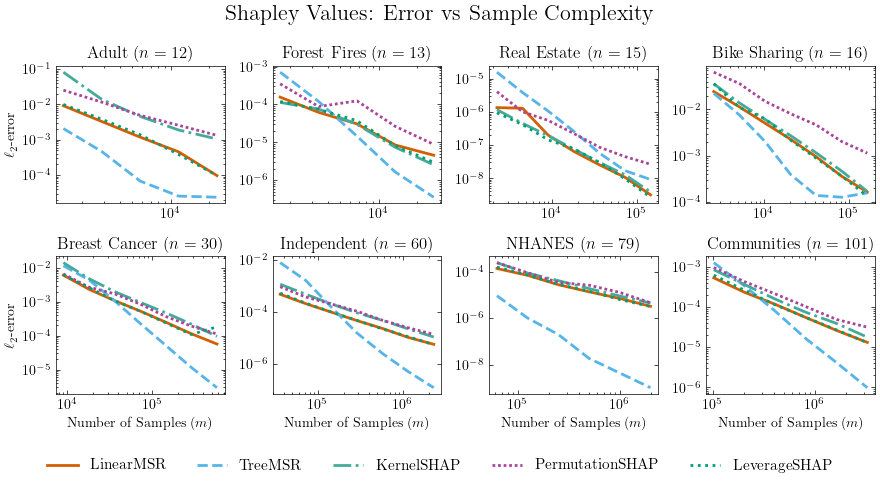

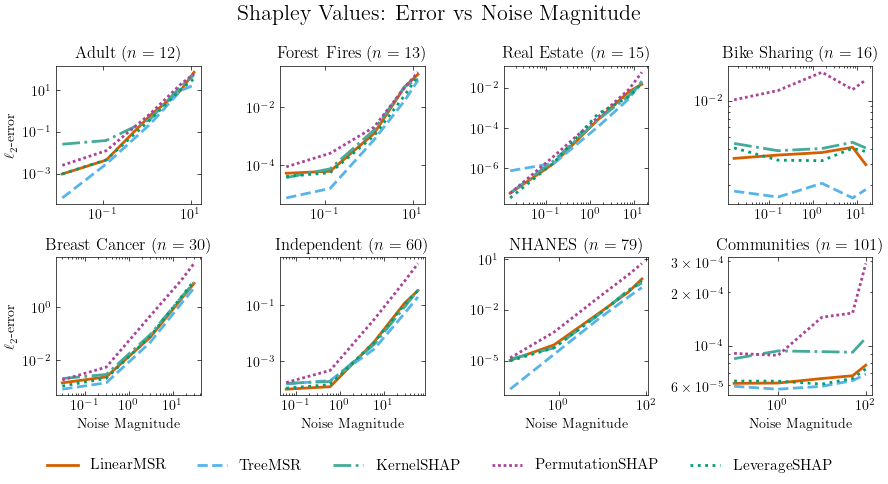

In [7]:
use_estimators = [
    'LinearMSR',
    'TreeMSR',
    'KernelSHAP',
    'PermutationSHAP',
    'LeverageSHAP',
    #'ARM',
    #'WeightedSHAP',
    #'GELS',
]

# Define datasets and parameters

for extra_variable in ['sample_size', 'noise']:
    extra_variable_vals = np.array(VARIABLES[extra_variable][extra_variable])
    filter = {'sample_size': [40], 'noise': [0]}
    filter[extra_variable] = extra_variable_vals

    # Load filtered error results
    results = load_filtered_error(filter, extra_variable=extra_variable)

    datasets = results.keys()  # Assuming results contain dataset keys
    if len(datasets) == 0:
        print(f'No results found for extra variable: {extra_variable}')
        continue
    fig, axs = plt.subplots(2, len(datasets)//2, figsize=(9, 4.5))
    all_handles = {}

    # Iterate through datasets
    # Sort the datasets by the number of samples
    datasets = sorted(datasets, key=lambda x: dataset_sizes[x])
    for j, dataset in enumerate(datasets):
        if 'shapley' not in results[dataset]:
            continue
        row = j // (len(datasets)//2)
        col = j % (len(datasets)//2)
        ax = axs[row, col]
        
        for estimator_idx, estimator in enumerate(use_estimators):

            if estimator not in results[dataset]['shapley']:
                continue
            
            errors = {'mean': [], 'median': [], '1st': [], '3rd': [], 'xaxis': []}
            for val in extra_variable_vals:
                adjusted_val = val
                if extra_variable == 'sample_size':  
                    # Adjust the value based on the dataset size
                    adjusted_val = int(dataset_sizes[dataset] * val)            
                if adjusted_val in results[dataset]['shapley'][estimator]:
                    errors['xaxis'].append(adjusted_val * dataset_sizes[dataset])
                    errors['mean'].append(np.mean(results[dataset]['shapley'][estimator][adjusted_val]))
                    errors['median'].append(np.median(results[dataset]['shapley'][estimator][adjusted_val]))
                    errors['1st'].append(np.quantile(results[dataset]['shapley'][estimator][adjusted_val], 0.25))
                    errors['3rd'].append(np.quantile(results[dataset]['shapley'][estimator][adjusted_val], 0.75))

            # Add intervals between 1st and 3rd quartiles
            #ax.fill_between(extra_variable_vals * dataset_sizes[dataset], errors['1st'], errors['3rd'], alpha=0.2, color=cb_colors[estimator_idx], linewidth=0)
            line, = ax.plot(errors['xaxis'], errors['mean'],
                                label=estimator,
                                linestyle=linestyles[estimator_idx],
                                color=cb_colors[estimator_idx], linewidth=2)
            
            if estimator not in all_handles:
                all_handles[estimator] = line
        
        if col == 0:
            ax.set_ylabel(r'$\ell_2$-error')
        if row == 1:
            xlabel = 'Number of Samples ($m$)' if extra_variable == 'sample_size' else 'Noise Magnitude'
            ax.set_xlabel(xlabel)
        ax.set_yscale('log')
        ax.set_xscale('log')
        ax.set_title(f'{dataset} ($n={dataset_sizes[dataset]}$)')

    # Overall figure title and legend
    error_vs = 'Sample Complexity' if extra_variable == 'sample_size' else 'Noise Magnitude'
    fig.suptitle('Shapley Values: Error vs ' + error_vs, fontsize=16)
    fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', 
            ncol=5, bbox_to_anchor=(0.5, 0), fontsize=11)
    plt.tight_layout()
    filename_ender = '_sample_size' if extra_variable == 'sample_size' else '_noise'
    plt.savefig(f'images/shapley{filename_ender}.pdf', bbox_inches='tight', dpi=300)
    plt.show()

In [8]:
def fancy_round(x, precision=2):
    return f"{x:.{precision}e}"

def one_big_table(results, filename, datasets, dataset_labels, use_estimators):
    # Each column is a dataset
    # There are several groups of rows: one for each method
    # Each group has 4 rows: mean, 1st quartile, 2nd quartile, 3rd quartile
    num_methods = len(use_estimators)
    table = np.zeros((num_methods*4, len(results)))
    for i, dataset in enumerate(datasets):
        for j, method in enumerate(use_estimators):
            if method not in results[dataset]:
                table[j*4:(j+1)*4, i] = np.nan
                continue
            values = np.array(results[dataset][method])
            mean = np.mean(values)
            median = np.median(values)
            upper = np.percentile(values, 75)
            lower = np.percentile(values, 25)
            to_add = np.array([mean, lower, median, upper])
            table[j*4:(j+1)*4, i] = to_add
    # Look at mean errors
    # Consider ratio of LinearMSR to all other methods and print out average ratio
    # Add column that averages all rows
    table = np.concatenate((table, np.mean(table, axis=1).reshape(-1, 1)), axis=1)
    j_linear = use_estimators.index('LinearMSR')
    j_tree = use_estimators.index('TreeMSR')

    for j, method in enumerate(use_estimators):
        if method not in results[dataset]: continue
        ratio = table[j_linear*4:(j_linear+1)*4, :] / table[j*4:(j+1)*4, :]
        print(f'{method} vs LinearMSR: {np.mean(ratio):.2f} +/- {np.std(ratio):.2f}')

        ratio = table[j_tree*4:(j_tree+1)*4, :] / table[j*4:(j+1)*4, :]
        print(f'{method} vs TreeMSR: {np.mean(ratio):.2f} +/- {np.std(ratio):.2f}')

        try:
            j_leverage = use_estimators.index('LeverageSHAP')
            ratio = table[j_leverage*4:(j_leverage+1)*4, :] / table[j*4:(j+1)*4, :]
            print(f'{method} vs LeverageSHAP: {np.mean(ratio):.2f} +/- {np.std(ratio):.2f}')
        except ValueError:
            pass


    with open(filename, 'w') as f:
        f.write('\\resizebox{\\linewidth}{!}{ \n')
        f.write('\\begin{tabular} {l'+ 'c'*(len(results)) +'|c'+ '}\n')
        f.write('\\hline\n')
        f.write(' & ' + ' & '.join([f'\\textbf{{{dataset}}}' for dataset in dataset_labels + ['Mean']]) + ' \\\\ \n')
#        f.write('\\hline\n')
        i = 0
        for method in use_estimators:
            method = method.replace('_S', '')
            f.write('\\hline \n')
            f.write(f'\\textbf{{{method}}}' + ' & ' * len(results) + ' \\\\ \n')
            #f.write('\\hline \n')
            for metric in ['Mean', '1st Quartile', '2nd Quartile', '3rd Quartile']:
                row = [] 
                for j in range(len(results)+1):
                    # Color the best, second, third values with gold, silver, bronze
                    # Select every 4th row

                    relevant_col = sorted(table[(i%4)::4,j])
                    color = ''
                    if table[i,j] == relevant_col[0]:
                        color = '\\cellcolor{gold!60}'
                    elif table[i,j] == relevant_col[1]:
                        color = '\\cellcolor{silver!60}'
                    elif table[i,j] == relevant_col[2]:
                        color = '\\cellcolor{bronze!60}'
                    #row += [color + '$' + str(fancy_round(table[i,j])) + '$']
                    row += [color + '$\\num{' + str(fancy_round(table[i,j])) + '}$']
                start = '\\hspace{7pt}' + metric + ' & '
                f.write(start + ' & '.join([str(x) for x in row]) + ' \\\\ \n')
                i += 1
        f.write('\\hline\n')
        f.write('\\end{tabular}}') 

# Load filtered error results
results = load_filtered_error({'sample_size': [40], 'noise': [0]})
datasets = sorted(results.keys(), key=lambda x: dataset_sizes[x])

# Remove shapley
for dataset in results:
    if 'shapley' in results[dataset]:
        results[dataset] = results[dataset]['shapley']
    else:
        del results[dataset]

one_big_table(results, 'tables/shapley.tex', datasets, datasets, use_estimators)

LinearMSR vs LinearMSR: 1.00 +/- 0.00
LinearMSR vs TreeMSR: 1.16 +/- 1.60
LinearMSR vs LeverageSHAP: 0.94 +/- 0.28
TreeMSR vs LinearMSR: 289.33 +/- 1281.20
TreeMSR vs TreeMSR: 1.00 +/- 0.00
TreeMSR vs LeverageSHAP: 277.73 +/- 1194.81
KernelSHAP vs LinearMSR: 37915.94 +/- 224305.54
KernelSHAP vs TreeMSR: 51902.40 +/- 307037.41
KernelSHAP vs LeverageSHAP: 0.70 +/- 0.19
PermutationSHAP vs LinearMSR: 37915.31 +/- 224305.72
PermutationSHAP vs TreeMSR: 51900.23 +/- 307037.87
PermutationSHAP vs LeverageSHAP: 0.53 +/- 0.28
LeverageSHAP vs LinearMSR: 37916.46 +/- 224305.51
LeverageSHAP vs TreeMSR: 51903.54 +/- 307037.29
LeverageSHAP vs LeverageSHAP: 1.00 +/- 0.00


/var/folders/qq/hk_0lt914qn6ny3hn40bvg3r0000gn/T/ipykernel_40357/873099508.py:28: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


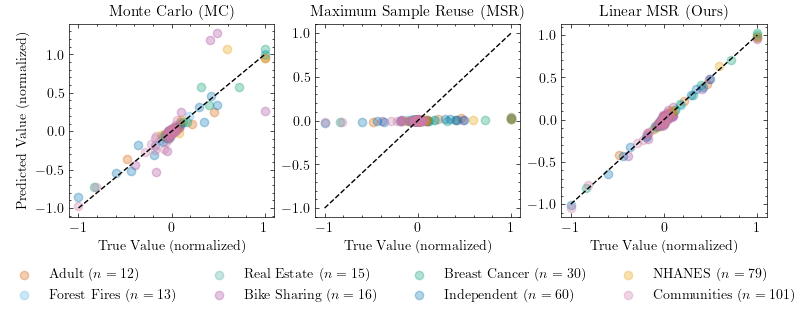

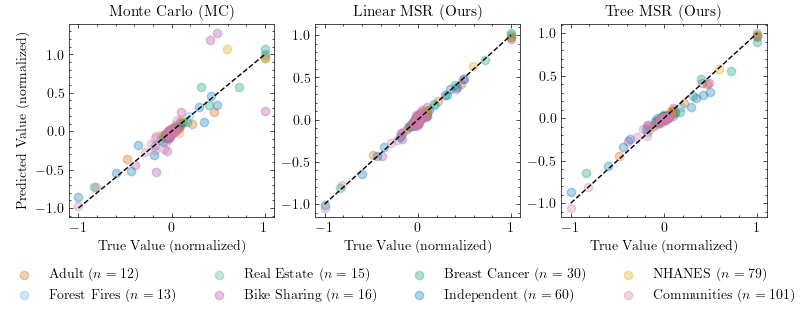

In [9]:
estimator_lookup = {'WSL': 'Monte Carlo (MC)', 'MSR': 'Maximum Sample Reuse (MSR)', 'LinearMSR': 'Linear MSR (Ours)', 'LeverageSHAP': 'LeverageSHAP', 'TreeMSR': 'Tree MSR (Ours)'}

for use_estimators, weighting in zip([['WSL', 'MSR', 'LinearMSR'], ['WSL', 'LinearMSR', 'TreeMSR']], ['shapley', 'shapley']):

    fig, axs = plt.subplots(1, len(use_estimators), figsize=(9, 2.5))

    for j, dataset in enumerate(datasets):
        filename = f'output/case_study_{dataset}_{weighting}.csv'
        with open(filename, 'r') as f:
            for line in f:
                dict = eval(line.replace('array', 'np.array'))
            true_values = dict['True'][0]
            max_val = np.max(np.abs(true_values))

            for i, estimator in enumerate(use_estimators):
                pred_values = dict[estimator]
                axs[i].scatter(true_values/max_val, pred_values/max_val, label=rf'{dataset} ($n={dataset_sizes[dataset]}$)', color=cb_colors[j], alpha=0.3, marker='o')

    for i, estimator in enumerate(use_estimators):
        # Draw the diagonal line
        axs[i].plot([-1, 1], [-1, 1], linestyle='--', color='black', linewidth=1, alpha=1)
        axs[i].set_title(f'{estimator_lookup[estimator]}', fontsize=11)
        axs[i].set_xlabel('True Value (normalized)')
        if i == 0:
            axs[i].set_ylabel('Predicted Value (normalized)')

    plt.legend(fancybox=True, bbox_to_anchor=(1.2,-.2), ncol=4)
    plt.tight_layout()
    plt.savefig(f'images/case_study_{weighting}.pdf', bbox_inches='tight', dpi=300)

### Probabilistic Values

In [10]:
# Load filtered error results
results = load_filtered_error(
    {'sample_size': [40], 'noise': [0]}
)

def combine_datasets(results, dataset_group=None):
    fixed_dataset = 'Communities' # used for finding weights, estimators
    new_results = {
        weight: {
            estimator : [] for estimator in results[fixed_dataset][weight]
        } for weight in results[fixed_dataset]
    }
    for weight in results[fixed_dataset]:
        for estimator in results[fixed_dataset][weight]:
            errors = []
            for dataset in results.keys():
                if dataset_group is not None:
                    if dataset not in DATASETS[dataset_group]: continue
                errors += results[dataset][weight][estimator]
            new_results[weight][estimator] = errors
    return new_results

use_estimators = list(ESTIMATOR_ALL.keys())
use_estimators.remove('AME')

for dataset_group in ['small_n', 'big_n']:
    combined_results = combine_datasets(results, dataset_group)
    # Remove a lot of estimators
    weights, weights_labels = [], []
    for weight in weightings['Symmetric Beta'] + weightings['Asymmetric Beta'][1:] + weightings['Weighted Banzhaf']:
        if weight in ['shapley', 'banzhaf', 'beta_shapley_16_16', 'beta_shapley_1_16']:
            continue
        weights += [weight]
        weights_labels += [weight_lookup[weight]]
    for weight in ['shapley', 'banzhaf']:
        if weight in combined_results:
            del combined_results[weight]
    
    print(weights)
    one_big_table(combined_results, f'tables/probabilistic_{dataset_group}.tex', weights, weights_labels, use_estimators)
print(combined_results)

['beta_shapley_1_1', 'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9']
LinearMSR vs LinearMSR: 1.00 +/- 0.00
LinearMSR vs TreeMSR: 1.17 +/- 2.64
TreeMSR vs LinearMSR: 98.74 +/- 244.08
TreeMSR vs TreeMSR: 1.00 +/- 0.00
OFA_S vs LinearMSR: 0.17 +/- 0.47
OFA_S vs TreeMSR: 0.00 +/- 0.01
WSL vs LinearMSR: 0.05 +/- 0.09
WSL vs TreeMSR: 0.00 +/- 0.01
GELS vs LinearMSR: 0.06 +/- 0.12
GELS vs TreeMSR: 0.00 +/- 0.00
ARM vs LinearMSR: 0.08 +/- 0.16
ARM vs TreeMSR: 0.00 +/- 0.00
WeightedSHAP vs LinearMSR: 0.12 +/- 0.20
WeightedSHAP vs TreeMSR: 0.01 +/- 0.02
['beta_shapley_1_1', 'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9

['beta_shapley_1_1', 'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_16_16']
['beta_shapley_1_1', 'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'beta_shapley_1_16']
['weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9']


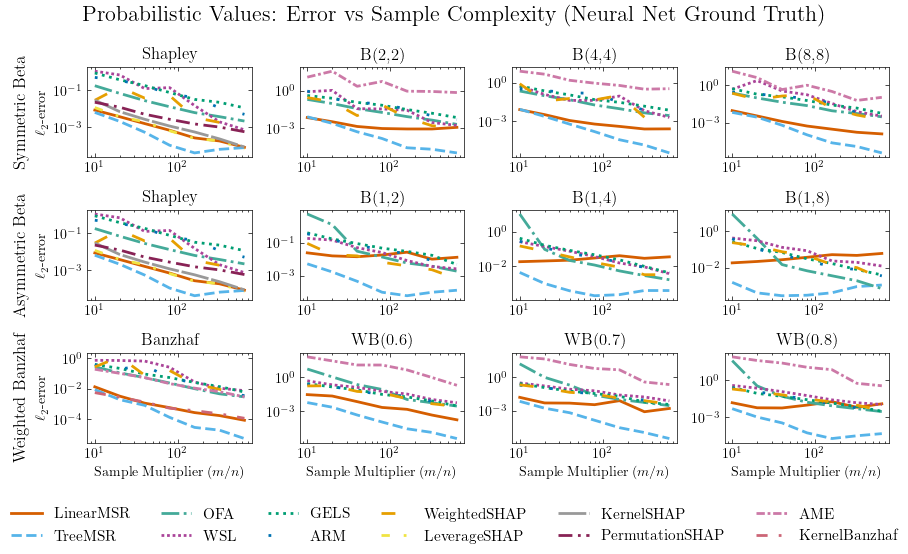

['beta_shapley_1_1', 'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_16_16']
['beta_shapley_1_1', 'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'beta_shapley_1_16']
['weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9']


<Figure size 350x262.5 with 0 Axes>

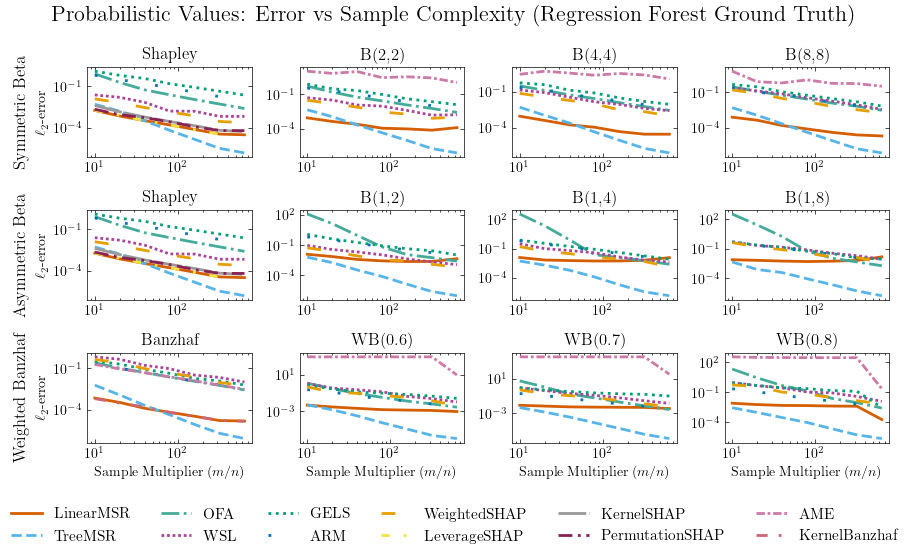

['beta_shapley_1_1', 'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_16_16']
['beta_shapley_1_1', 'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'beta_shapley_1_16']
['weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9']


<Figure size 350x262.5 with 0 Axes>

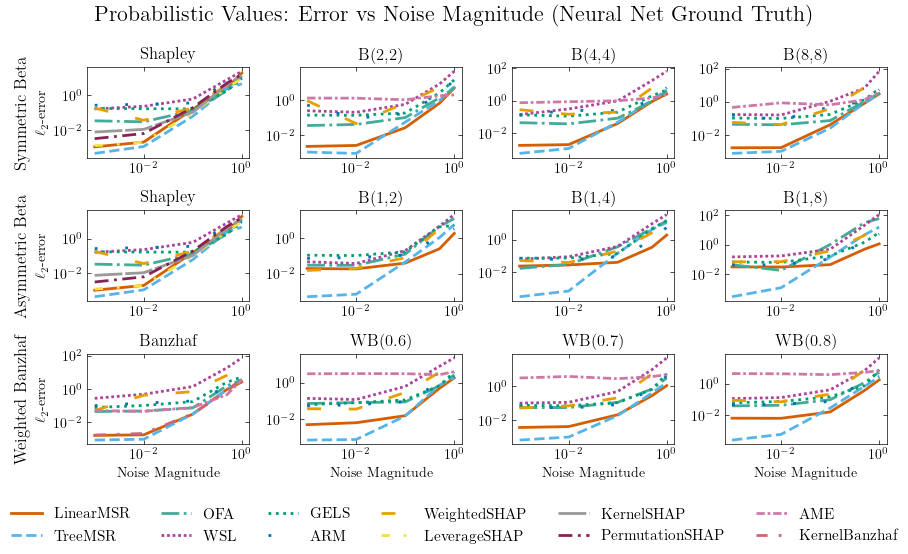

['beta_shapley_1_1', 'beta_shapley_2_2', 'beta_shapley_4_4', 'beta_shapley_8_8', 'beta_shapley_16_16']
['beta_shapley_1_1', 'beta_shapley_1_2', 'beta_shapley_1_4', 'beta_shapley_1_8', 'beta_shapley_1_16']
['weighted_banzhaf_0.5', 'weighted_banzhaf_0.6', 'weighted_banzhaf_0.7', 'weighted_banzhaf_0.8', 'weighted_banzhaf_0.9']


<Figure size 350x262.5 with 0 Axes>

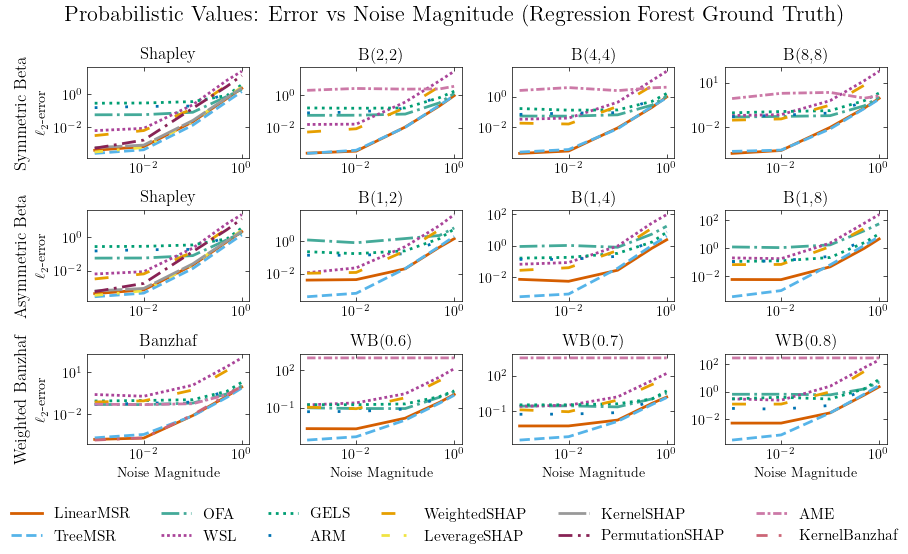

<Figure size 350x262.5 with 0 Axes>

In [14]:
# Make a giant plot
# The columns are the datasets
# The rows are the weightings i.e., beta_shapley_sym, beta_shapley_asym, weighted_banzhaf
# Each subplot is a line plot of the error for each estimator and the x axis is the number of samples on one of the weightings in the class of the row



for extra_variable in ['sample_size', 'noise']:
    extra_variable_vals = VARIABLES[extra_variable][extra_variable]

    filter = {'sample_size':[40], 'noise':[0]}
    filter[extra_variable] = extra_variable_vals

    exclude_estimators = ['Tree']

    results = load_filtered_error(filter, extra_variable=extra_variable)
    make_smaller = 1

    for dataset_group in ['small_n', 'big_n']:
        fig, axs = plt.subplots(len(weightings), 5-make_smaller, figsize=(9, 5))

        all_handles = {}
        for i, (weight_list_name, weight_list) in enumerate(weightings.items()):
            print(weight_list)
            for j, weight in enumerate(weight_list):
                if j == len(weight_list) - make_smaller: continue
                if weight == 'beta_shapley_1_1':
                    weight = 'shapley'
                if weight == 'weighted_banzhaf_0.5':
                    weight = 'banzhaf'
                for estimator_idx, estimator in enumerate(ESTIMATOR_FACTORY.keys()):
                    if estimator in exclude_estimators: continue
                    if weight not in results[dataset]: continue
                    if estimator not in results[dataset][weight]: continue
                    errors = {'mean':[], 'median':[], '1st':[], '3rd':[]}
                    for val in extra_variable_vals:
                        val_errors = []
                        for dataset in DATASETS[dataset_group]:
                            actual_sample_size = val
                            if extra_variable == 'sample_size':
                                actual_sample_size = int(dataset_sizes[dataset]*val) 
                            if actual_sample_size in results[dataset][weight][estimator]:
                                val_errors += [np.mean(results[dataset][weight][estimator][actual_sample_size])]
                        errors['mean'].append(np.mean(val_errors))
                        errors['median'].append(np.median(val_errors))
                        errors['1st'].append(np.percentile(val_errors, 25))
                        errors['3rd'].append(np.percentile(val_errors, 75))

                    line, = axs[i, j].plot(
                        extra_variable_vals, errors['mean'], 
                        label=estimator.replace('_S', ''), 
                        linestyle=linestyles[estimator_idx], 
                        color=cb_colors[estimator_idx],
                        linewidth=2
                    )

                    # Add the line handle to the global collection
                    if estimator not in all_handles:
                        all_handles[estimator.replace('_S',"")] = line
                axs[i, j].set_yscale('log')
                axs[i, j].set_xscale('log')
                axs[i, j].set_title(weight_lookup[weight])
                if i == 2:
                    xlabel = r'Sample Multiplier ($m/n$)' if extra_variable == 'sample_size' else 'Noise Magnitude'
                    axs[i,j].set_xlabel(xlabel)
                if j == 0:
                    axs[i,j].set_ylabel(r'$\ell_2$-error')
                    axs[i,j].annotate(weight_list_name,
                    xy=(-.4, 0.5),              # Coordinates in axis fraction
                    xycoords='axes fraction', # Relative to the axis
                    fontsize=12,
                    rotation=90,              # Rotate to align with y-axis
                    ha='center',              # Centered horizontally
                    va='center',              # Centered vertically
                    color='black')

        nice_group_name = {'small_n' : r'(Neural Net Ground Truth)', 'big_n' : r'(Regression Forest Ground Truth)'}[dataset_group]

        error_vs = ' Sample Complexity ' if extra_variable == 'sample_size' else ' Noise Magnitude '
        fig.suptitle('Probabilistic Values: Error vs' + error_vs + nice_group_name, fontsize=16)
        # Two layers of legends
        fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', 
            ncol=6, bbox_to_anchor=(0.5, 0), fontsize=11)
        #fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', ncol=6, bbox_to_anchor=(0.45,0), fontsize=11)
        plt.tight_layout()
        filename_ender = '' if extra_variable == 'sample_size' else '_noise'
        plt.savefig(f'images/prob_complexity_{dataset_group}{filename_ender}.pdf',bbox_inches='tight', dpi=300)
        plt.show()
        plt.clf()

In [12]:
## Make a giant plot
## The columns are the datasets
## The rows are the weightings i.e., beta_shapley_sym, beta_shapley_asym, weighted_banzhaf
## Each subplot is a line plot of the error for each estimator
#
#filter = {
#    'sample_size' : [10],
#    'noise' : [0]
#}
#results = load_filtered_error(filter)
#
#use_estimators = [
#    'LinearMSR',
#    'TreeMSR',
#    'LeverageSHAP',
#    'PermutationSHAP',
#    'KernelSHAP', 
#    'WSL',
#    'OFA_S',
#]
#
#filename = 'images/prob_datasets.pdf'
#
#
#fig, axs = plt.subplots(len(weightings), len(dataset_names), figsize=(20, 5.5))
#
#all_handles = {}
#for i, (weight_list_name, weight_list) in enumerate(weightings.items()):
#    for j, dataset in enumerate(dataset_names):
#        if i == 0:
#            axs[i, j].set_title(fr'{dataset} ($n={dataset_sizes[dataset]}$)')
#        if j == 0:
#            axs[i, j].set_ylabel(fr'$\ell_2$-error')
#            axs[i,j].annotate(weight_list_name,
#                xy=(-.75, 0.5),              # Coordinates in axis fraction
#                xycoords='axes fraction', # Relative to the axis
#                fontsize=12,
#                rotation=90,              # Rotate to align with y-axis
#                ha='center',              # Centered horizontally
#                va='center',              # Centered vertically
#                color='black')
#        for estimator_idx, estimator in enumerate(use_estimators):
#            if weight_list[-2] not in results[dataset]:
#                continue
#            if estimator not in results[dataset][weight_list[-2]]:
#                continue
#            errors = [np.mean(results[dataset][weighting][estimator]) for weighting in weight_list]
#            prettier_weight_list = [weight_lookup[weighting] for weighting in weight_list]
#        
#            # Rotate the x-axis labels
#            axs[i, j].set_xticks(np.arange(len(prettier_weight_list)))
#            axs[i, j].set_xticklabels(prettier_weight_list, rotation=30)
#            line, = axs[i, j].plot(prettier_weight_list, errors, 
#                                label=estimator, 
#                                linestyle=linestyles[estimator_idx], 
#                                color=cb_colors[estimator_idx], linewidth=2)
#
#            # Add the line handle to the global collection
#            if estimator not in all_handles:
#                all_handles[estimator] = line
#        axs[i, j].set_yscale('log')
#
#fig.suptitle('Probabilistic Value Estimator Error by Dataset', fontsize=16)
## Two layers of legends
#fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', ncol=len(all_handles), bbox_to_anchor=(0.45,0), fontsize=11)
#
#plt.tight_layout()
#
#plt.savefig(filename, bbox_inches='tight', dpi=300)
#plt.show()

## Quality of Fit

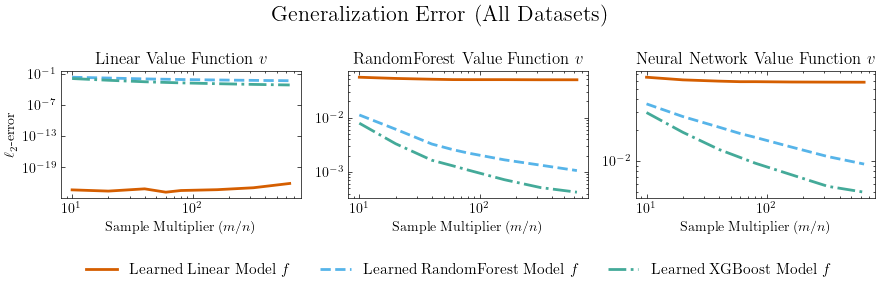

In [15]:

# The columns are the ground_truth_class
# Each subplot is a line plot of the error for reg_model_class and the x axis is the number of samples

fig, axs = plt.subplots(1, 3, figsize=(9, 2.5))

all_handles = {}
for i, ground_truth_class in enumerate(['Linear', 'RandomForest', 'NeuralNet']):
    fit_errors = {}
    for j, dataset in enumerate(dataset_names):
        fit_errors_dataset = load_fit_error(dataset, ground_truth_class)
        for estimator in fit_errors_dataset:
            if estimator not in fit_errors:
                fit_errors[estimator] = {}
            for sample_multiplier in fit_errors_dataset[estimator]:
                if sample_multiplier not in fit_errors[estimator]:
                    fit_errors[estimator][sample_multiplier] = []
                fit_errors[estimator][sample_multiplier] += fit_errors_dataset[estimator][sample_multiplier]

    for reg_model_class_idx, reg_model_class in enumerate(fit_errors.keys()):
        errors = {'mean':[], 'median':[], '1st':[], '3rd':[]}
        sample_multipliers = []
        for val in fit_errors[reg_model_class]:
            errors['mean'].append(np.mean(fit_errors[reg_model_class][val]))
            errors['median'].append(np.median(fit_errors[reg_model_class][val]))
            errors['1st'].append(np.percentile(fit_errors[reg_model_class][val], 25))
            errors['3rd'].append(np.percentile(fit_errors[reg_model_class][val], 75))
            sample_multipliers += [val]


        # Add interval between 1st and 3rd quartile
        #axs[i].fill_between(sample_multipliers, errors['1st'], errors['3rd'], alpha=0.2, color=cb_colors[reg_model_class_idx])
        line, = axs[i].plot(sample_multipliers, errors['mean'], 
            label=reg_model_class + ' Learned Model', 
            linestyle=linestyles[reg_model_class_idx], 
            color=cb_colors[reg_model_class_idx],
            linewidth=2)

        # Add the line handle to the global collection
        if reg_model_class not in all_handles:
            all_handles['Learned '+ reg_model_class + f' Model $f$'] = line
    axs[i].set_yscale('log')
    axs[i].set_xscale('log')
    if ground_truth_class == 'NeuralNet':
        ground_truth_class = 'Neural Network'
    axs[i].set_title(fr'{ground_truth_class} Value Function $v$')
    if i == 0:
        axs[i].set_ylabel(fr'$\ell_2$-error')

    axs[i].set_xlabel(r'Sample Multiplier ($m/n$)')


fig.suptitle(f'Generalization Error (All Datasets)', fontsize=16)
# Two layers of legends
fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', ncol=len(all_handles), bbox_to_anchor=(0.52,0), fontsize=11)

plt.tight_layout()
plt.savefig('images/fit_sample_complexity.pdf', bbox_inches='tight', dpi=300)
plt.show()

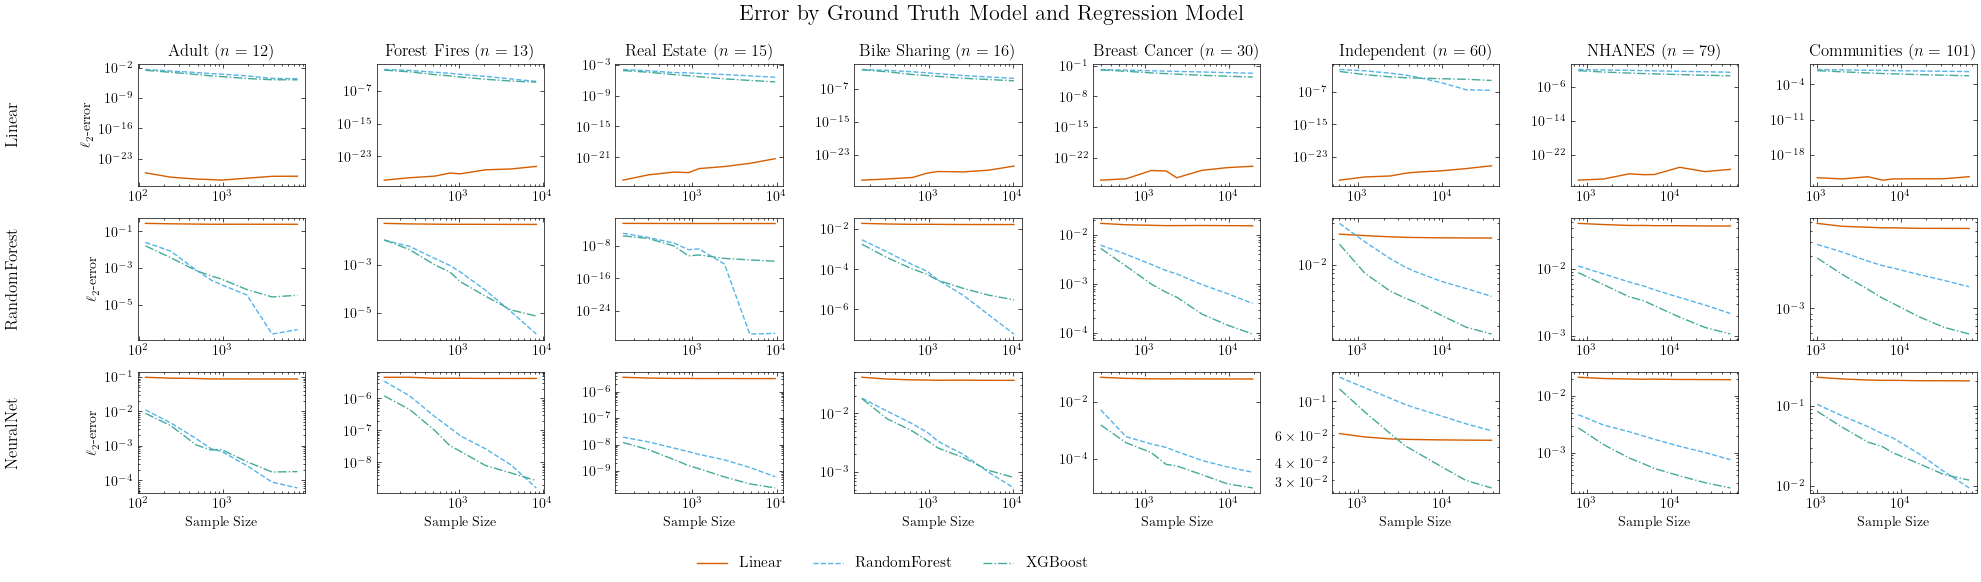

In [17]:
# Make a giant plot
# The columns are the datasets
# The rows are the ground_truth_class
# Each subplot is a line plot of the error for reg_model_class and the x axis is the number of samples

fig, axs = plt.subplots(3, len(datasets), figsize=(20, 5.5))

all_handles = {}
for i, ground_truth_class in enumerate(['Linear', 'RandomForest', 'NeuralNet']):
    for j, dataset in enumerate(dataset_names):
        fit_errors = load_fit_error(dataset, ground_truth_class)
        for reg_model_class_idx, reg_model_class in enumerate(fit_errors.keys()):
            errors = []
            num_samples = []
            for val in fit_errors[reg_model_class]:
                errors.append(np.mean(fit_errors[reg_model_class][val]))
                num_samples += [int(dataset_sizes[dataset]*val)]

            line, = axs[i, j].plot(num_samples, errors, 
                                   label=reg_model_class, 
                                   linestyle=linestyles[reg_model_class_idx], 
                                   color=cb_colors[reg_model_class_idx])

            # Add the line handle to the global collection
            if reg_model_class not in all_handles:
                all_handles[reg_model_class] = line
        axs[i, j].set_yscale('log')
        axs[i, j].set_xscale('log')
        if i == 0:
            axs[i, j].set_title(fr'{dataset} ($n={dataset_sizes[dataset]}$)')
        if j == 0:
            axs[i, j].set_ylabel(fr'$\ell_2$-error')
            axs[i,j].annotate(ground_truth_class,
                xy=(-.75, 0.5),              # Coordinates in axis fraction
                xycoords='axes fraction', # Relative to the axis
                fontsize=12,
                rotation=90,              # Rotate to align with y-axis
                ha='center',              # Centered horizontally
                va='center',              # Centered vertically
                color='black')
        if i == 2:
            axs[i, j].set_xlabel('Sample Size')


fig.suptitle(f'Error by Ground Truth Model and Regression Model', fontsize=16)
# Two layers of legends
fig.legend(all_handles.values(), all_handles.keys(), loc='upper center', ncol=len(all_handles), bbox_to_anchor=(0.45,0), fontsize=11)
#for i in range(3):
#    ylims = [ax.get_ylim() for ax in axs[i, :]]
#
#    shared_ylim = (min(y[0] for y in ylims), max(y[1] for y in ylims))
#
#    for ax in axs[i, :]:
#        ax.set_ylim(shared_ylim)

plt.tight_layout()
plt.savefig('images/fit_datasets.pdf', bbox_inches='tight', dpi=300)
plt.show()